Dataset after preprocessing: (150389, 6)

Correlation:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000         -0.055993        -0.087178   
pickup_longitude     -0.055993          1.000000         0.679176   
pickup_latitude      -0.087178          0.679176         1.000000   
dropoff_longitude     0.004653          0.405814         0.319188   
dropoff_latitude     -0.107743          0.349402         0.512692   
passenger_count       0.016739         -0.022527        -0.019421   

                   dropoff_longitude  dropoff_latitude  passenger_count  
fare_amount                 0.004653         -0.107743         0.016739  
pickup_longitude            0.405814          0.349402        -0.022527  
pickup_latitude             0.319188          0.512692        -0.019421  
dropoff_longitude           1.000000          0.612429        -0.015159  
dropoff_latitude            0.612429          1.000000        -0.012177  
passenger_count  

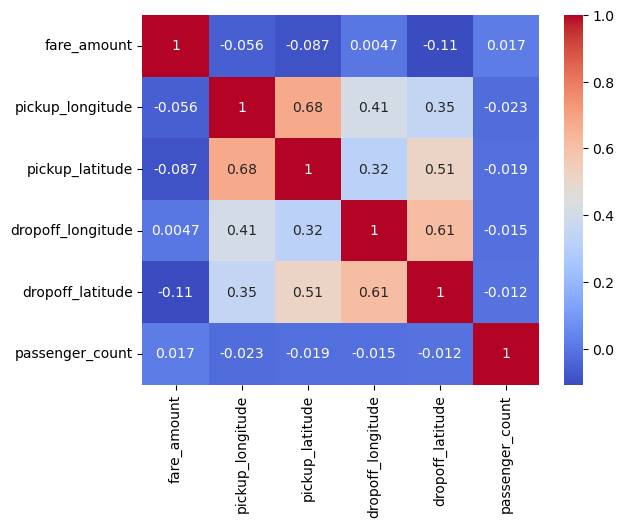


 Linear Regression
R2 Score: 0.018890252428274024
MAE: 3.0868033362638614
RMSE: 3.8936248856245985

 Ridge Regression
R2 Score: 0.019049727723285614
MAE: 3.0868393126428124
RMSE: 3.893308426526335

 Lasso Regression
R2 Score: -6.796405068065781e-06
MAE: 3.1189937275865454
RMSE: 3.9309433898484887


In [3]:
'''Regression Analysis:
A. Predict the price of the Uber ride from a given pickup point to the agreed drop-off 
location. Perform following tasks:  
1. Pre-process the dataset.  
2. Identify outliers.  
3. Check the correlation.  
4. Implement linear regression and ridge, Lasso regression models.  
5. Evaluate the models and compare their respective scores like R2, RMSE, etc.  
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset '''
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load dataset
df = pd.read_csv("uber.csv")

# 1. Pre-processing
df = df.drop(['Unnamed: 0', 'key', 'pickup_datetime'], axis=1)
df = df.dropna()

# Remove invalid values
df = df[(df['fare_amount'] > 0) &
        (df['passenger_count'] > 0)]

# 2. Identify and remove outliers using IQR
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

df = df[~((df < (Q1 - 1.5 * IQR)) |
          (df > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Dataset after preprocessing:", df.shape)

# 3. Check correlation
print("\nCorrelation:")
print(df.corr())

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

plt.show()

# 4. Split data
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Ridge Regression
ridge = Ridge()
ridge.fit(X_train, y_train)

# Lasso Regression
lasso = Lasso()
lasso.fit(X_train, y_train)

# 5. Evaluate models
models = {
    "Linear Regression": lr,
    "Ridge Regression": ridge,
    "Lasso Regression": lasso
}

for name, model in models.items():
    y_pred = model.predict(X_test)

    print("\n", name)
    print("R2 Score:", r2_score(y_test, y_pred))
    print("MAE:", mean_absolute_error(y_test, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))